In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [10]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os

dataset_path = "/content/drive/MyDrive/RSNA_Pneumonia/rsna-pneumonia-detection-challenge.zip"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    size_gb = os.path.getsize(dataset_path) / (1024**3)
    print(f"Dataset size: {size_gb:.2f} GB")
else:
    print("Dataset not found at the specified path.")

Dataset exists: True
Dataset size: 3.66 GB


In [14]:
import os

zip_path = "/content/drive/MyDrive/RSNA_Pneumonia/rsna-pneumonia-detection-challenge.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    size_gb = os.path.getsize(zip_path) / (1024**3)
    print(f"ZIP size: {size_gb:.2f} GB")

print("\nFirst 30 files inside the dataset:")
!unzip -l "$zip_path" | head -35

ZIP exists: True
ZIP size: 3.66 GB

First 30 files inside the dataset:
Archive:  /content/drive/MyDrive/RSNA_Pneumonia/rsna-pneumonia-detection-challenge.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
       55  2019-12-11 23:47   GCP Credits Request Link - RSNA.txt
  1647396  2019-12-11 23:47   stage_2_detailed_class_info.csv
   159027  2019-12-11 23:47   stage_2_sample_submission.csv
   125100  2019-12-11 23:47   stage_2_test_images/0000a175-0e68-4ca4-b1af-167204a7e0bc.dcm
   159200  2019-12-11 23:47   stage_2_test_images/0005d3cc-3c3f-40b9-93c3-46231c3eb813.dcm
   172902  2019-12-11 23:47   stage_2_test_images/000686d7-f4fc-448d-97a0-44fa9c5d3aa6.dcm
   161660  2019-12-11 23:47   stage_2_test_images/000e3a7d-c0ca-4349-bb26-5af2d8993c3d.dcm
   154692  2019-12-11 23:47   stage_2_test_images/00100a24-854d-423d-a092-edcf6179e061.dcm
   118254  2019-12-11 23:47   stage_2_test_images/0015597f-2d69-4bc7-b642-5b5e01534676.dcm
   156392  2019-12-11 23:47   stage_2_

In [15]:
import os

zip_path = "/content/drive/MyDrive/RSNA_Pneumonia/rsna-pneumonia-detection-challenge.zip"
extract_path = "/content/rsna_data"

os.makedirs(extract_path, exist_ok=True)

print("Starting extraction...")

Starting extraction...


In [16]:
!unzip -q "$zip_path" -d "$extract_path"

print("Extraction completed!")

Extraction completed!


In [17]:
!ls -lh /content/rsna_data

total 5.2M
-rw-r--r-- 1 root root   55 Dec 11  2019 'GCP Credits Request Link - RSNA.txt'
-rw-r--r-- 1 root root 1.6M Dec 11  2019  stage_2_detailed_class_info.csv
-rw-r--r-- 1 root root 156K Dec 11  2019  stage_2_sample_submission.csv
drwxr-xr-x 2 root root 208K Sep 14 10:14  stage_2_test_images
drwxr-xr-x 2 root root 1.8M Sep 14 10:15  stage_2_train_images
-rw-r--r-- 1 root root 1.5M Dec 11  2019  stage_2_train_labels.csv


In [18]:
import pandas as pd

labels_path = "/content/rsna_data/stage_2_train_labels.csv"

labels_df = pd.read_csv(labels_path)

print("Dataset shape:", labels_df.shape)
print("\nColumns:")
print(labels_df.columns.tolist())

print("\nFirst 10 rows:")
display(labels_df.head(10))

Dataset shape: (30227, 6)

Columns:
['patientId', 'x', 'y', 'width', 'height', 'Target']

First 10 rows:


,patientId,x,y,width,height,Target
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1
5,00436515-870c-4b36-a041-de91049b9ab4,562.0,152.0,256.0,453.0,1
6,00569f44-917d-4c86-a842-81832af98c30,NaN,NaN,NaN,NaN,0
7,006cec2e-6ce2-4549-bffa-eadfcd1e9970,NaN,NaN,NaN,NaN,0
8,00704310-78a8-4b38-8475-49f4573b2dbb,323.0,577.0,160.0,104.0,1
9,00704310-78a8-4b38-8475-49f4573b2dbb,695.0,575.0,162.0,137.0,1


In [19]:
print("\nLabel distribution:")
print(labels_df["Target"].value_counts())

print("\nTarget percentages:")
print(labels_df["Target"].value_counts(normalize=True) * 100)


Label distribution:
Target
0    20672
1     9555
Name: count, dtype: int64

Target percentages:
Target
0    68.389188
1    31.610812
Name: proportion, dtype: float64


In [20]:
print("Total label rows:", len(labels_df))

print("Unique patient IDs:", labels_df["patientId"].nunique())

print("\nNumber of annotations per patient:")
print(labels_df["patientId"].value_counts().describe())

print("\nPatients with multiple annotation rows:")
multi_annotations = labels_df["patientId"].value_counts()
print((multi_annotations > 1).sum())

Total label rows: 30227
Unique patient IDs: 26684

Number of annotations per patient:
count    26684.000000
mean         1.132776
std          0.356362
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          4.000000
Name: count, dtype: float64

Patients with multiple annotation rows:
3398


In [21]:
# Create one classification label per X-ray.
# If any annotation for a patient has Target = 1,
# that X-ray is considered PNEUMONIA.

image_labels = (
    labels_df.groupby("patientId")["Target"]
    .max()
    .reset_index()
)

image_labels["label"] = image_labels["Target"].map({
    0: "NORMAL",
    1: "PNEUMONIA"
})

print("Unique X-rays:", len(image_labels))

print("\nFinal classification distribution:")
print(image_labels["label"].value_counts())

print("\nFinal percentages:")
print(image_labels["label"].value_counts(normalize=True) * 100)

display(image_labels.head(10))

Unique X-rays: 26684

Final classification distribution:
label
NORMAL       20672
PNEUMONIA     6012
Name: count, dtype: int64

Final percentages:
label
NORMAL       77.469645
PNEUMONIA    22.530355
Name: proportion, dtype: float64


,patientId,Target,label
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,0,NORMAL
1,000924cf-0f8d-42bd-9158-1af53881a557,0,NORMAL
2,000db696-cf54-4385-b10b-6b16fbb3f985,1,PNEUMONIA
3,000fe35a-2649-43d4-b027-e67796d412e0,1,PNEUMONIA
4,001031d9-f904-4a23-b3e5-2c088acd19c6,1,PNEUMONIA
5,0010f549-b242-4e94-87a8-57d79de215fc,0,NORMAL
6,001916b8-3d30-4935-a5d1-8eaddb1646cd,1,PNEUMONIA
7,0022073f-cec8-42ec-ab5f-bc2314649235,1,PNEUMONIA
8,0022995a-45eb-4cfa-9a59-cd15f5196c64,0,NORMAL
9,0025d2de-bd78-4d36-9f72-e15a5e22ca82,0,NORMAL


In [22]:
import os

image_dir = "/content/rsna_data/stage_2_train_images"

# Create the expected DICOM path for every X-ray
image_labels["image_path"] = image_labels["patientId"].apply(
    lambda x: os.path.join(image_dir, x + ".dcm")
)

# Check which files actually exist
image_labels["file_exists"] = image_labels["image_path"].apply(os.path.exists)

print("Total X-rays:", len(image_labels))
print("Images found:", image_labels["file_exists"].sum())
print("Images missing:", (~image_labels["file_exists"]).sum())

Total X-rays: 26684
Images found: 26684
Images missing: 0


In [24]:
!pip install -q pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 24.3 MB/s eta 0:00:00


In [25]:
import pydicom

sample_path = image_labels.loc[
    image_labels["file_exists"], "image_path"
].iloc[0]

dicom_data = pydicom.dcmread(sample_path)

print("Sample DICOM:")
print(dicom_data)

print("\nPixel array shape:", dicom_data.pixel_array.shape)
print("Pixel data type:", dicom_data.pixel_array.dtype)

Sample DICOM:
Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 202
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Secondary Capture Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.276.0.7230010.3.1.4.8323329.28530.1517874485.775526
(0002,0010) Transfer Syntax UID                 UI: JPEG Baseline (Process 1)
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.6.0
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_360'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0016) SOP Class UID                       UI: Secondary Capture Image Storage
(0008,0018) SOP Instance UID                    UI: 1.2.276.0.7230010.3.1.4.8323329.28530.1517874485.775526
(0008,0020) Study Date                          DA: '19010101'
(0008,0030) Study Time    

In [26]:
from sklearn.model_selection import train_test_split

# We only need these columns for the ML dataset
split_df = image_labels[[
    "patientId",
    "label",
    "image_path"
]].copy()

# First split:
# 70% training
# 30% temporary (validation + test)
train_df, temp_df = train_test_split(
    split_df,
    test_size=0.30,
    stratify=split_df["label"],
    random_state=42
)

# Second split:
# Divide the 30% temporary set equally
# → 15% validation
# → 15% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Dataset split completed!\n")

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Test samples:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Dataset split completed!

Training samples: 18678
Validation samples: 4003
Test samples: 4003

Total: 26684


In [27]:
print("TRAINING SET")
print(train_df["label"].value_counts())
print(train_df["label"].value_counts(normalize=True) * 100)

print("\nVALIDATION SET")
print(val_df["label"].value_counts())
print(val_df["label"].value_counts(normalize=True) * 100)

print("\nTEST SET")
print(test_df["label"].value_counts())
print(test_df["label"].value_counts(normalize=True) * 100)

TRAINING SET
label
NORMAL       14470
PNEUMONIA     4208
Name: count, dtype: int64
label
NORMAL       77.470821
PNEUMONIA    22.529179
Name: proportion, dtype: float64

VALIDATION SET
label
NORMAL       3101
PNEUMONIA     902
Name: count, dtype: int64
label
NORMAL       77.4669
PNEUMONIA    22.5331
Name: proportion, dtype: float64

TEST SET
label
NORMAL       3101
PNEUMONIA     902
Name: count, dtype: int64
label
NORMAL       77.4669
PNEUMONIA    22.5331
Name: proportion, dtype: float64


In [28]:
import os

split_dir = "/content/drive/MyDrive/RSNA_Pneumonia/splits"
os.makedirs(split_dir, exist_ok=True)

train_df.to_csv(
    os.path.join(split_dir, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(split_dir, "validation.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(split_dir, "test.csv"),
    index=False
)

print("Splits saved successfully!")
print("Location:", split_dir)

Splits saved successfully!
Location: /content/drive/MyDrive/RSNA_Pneumonia/splits


In [29]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

PyTorch version: 2.11.0+cu128
Torchvision version: 0.26.0+cu128
CUDA available: True
GPU: Tesla T4


In [30]:
from torch.utils.data import Dataset
import pydicom
import cv2
import numpy as np
import torch


class PneumoniaDataset(Dataset):

    def __init__(self, dataframe, image_size=224):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_size = image_size

        self.label_map = {
            "NORMAL": 0,
            "PNEUMONIA": 1
        }

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Read DICOM
        dicom = pydicom.dcmread(row["image_path"])
        image = dicom.pixel_array

        # Convert to uint8 if necessary
        if image.dtype != np.uint8:
            image = cv2.normalize(
                image,
                None,
                0,
                255,
                cv2.NORM_MINMAX
            ).astype(np.uint8)

        # Resize to 224 × 224
        image = cv2.resize(
            image,
            (self.image_size, self.image_size)
        )

        # Normalize to [0, 1]
        image = image.astype(np.float32) / 255.0

        # H × W → 1 × H × W
        image = torch.tensor(
            image,
            dtype=torch.float32
        ).unsqueeze(0)

        # Convert label to integer
        label = self.label_map[row["label"]]

        return image, torch.tensor(label, dtype=torch.long)

In [31]:
train_dataset = PneumoniaDataset(train_df)

print("Number of training samples:", len(train_dataset))

Number of training samples: 18678


In [32]:
image, label = train_dataset[0]

print("Image tensor shape:", image.shape)
print("Image data type:", image.dtype)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())
print("Label:", label.item())

Image tensor shape: torch.Size([1, 224, 224])
Image data type: torch.float32
Minimum pixel value: 0.0
Maximum pixel value: 0.9333333373069763
Label: 1


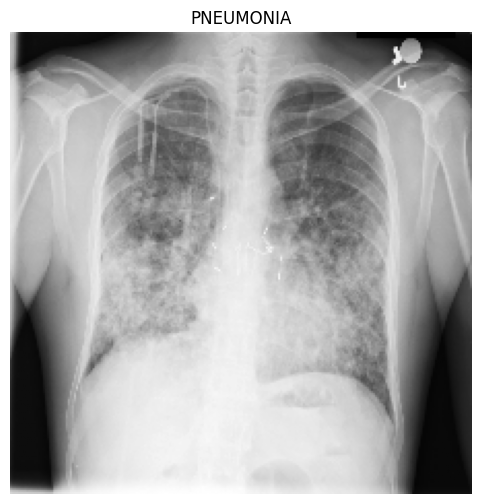

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))

plt.imshow(
    image.squeeze(0),
    cmap="gray"
)

plt.title(
    "PNEUMONIA" if label.item() == 1 else "NORMAL"
)

plt.axis("off")
plt.show()

In [34]:
from torch.utils.data import DataLoader

# Create datasets
train_dataset = PneumoniaDataset(train_df)
val_dataset = PneumoniaDataset(val_df)
test_dataset = PneumoniaDataset(test_df)

# Batch size
BATCH_SIZE = 32

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully!")

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

DataLoaders created successfully!

Training batches: 584
Validation batches: 126
Test batches: 126


In [35]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("Image minimum:", images.min().item())
print("Image maximum:", images.max().item())

print("\nLabels in this batch:")
print(labels)

Batch image shape: torch.Size([32, 1, 224, 224])
Batch label shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64
Image minimum: 0.0
Image maximum: 1.0

Labels in this batch:
tensor([1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1,
        1, 0, 1, 0, 1, 0, 0, 0])


In [36]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

print("Images device:", images.device)
print("Labels device:", labels.device)

Using device: cuda
Images device: cuda:0
Labels device: cuda:0


In [37]:
import torch
import torch.nn as nn


class CustomCNN(nn.Module):

    def __init__(self):
        super(CustomCNN, self).__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128 * 28 * 28,
                256
            ),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(
                256,
                2
            )
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [38]:
model = CustomCNN().to(device)

print(model)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=2, bias=True)
  )
)


In [39]:
model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 1, 224, 224])
Output shape: torch.Size([32, 2])
